# HW1. Задача 2: темы диалогов

Готового списка тем и разметки нет, поэтому сначала **находим темы** (кластеризация), потом **называем** их вручную, потом **учим классификатор** относить новый диалог к одной из тем. Инструменты со семинаров: TF-IDF и SVD (занятия 4–5), k-means, агломеративная кластеризация, GMM, DBSCAN и метрики кластеризации (занятие 5), Naive Bayes и ближайшие соседи (занятие 1), логистическая регрессия и SVM (3, 5), `GridSearchCV`, `joblib` (4).

План:
1. данные и признаки
2. разбиение
3. пространство для кластеризации (SVD) и выбор числа тем
4. темы: карточки, названия, описания
5. сверка с `task_type`
6. классификатор: три базовые модели и две свои
7. проверка устойчивости тем
8. разбор ошибок
9. метрики реакции по темам
10. сохранение

**Что здесь можно и нельзя доказать.** Темы получены кластеризацией, поэтому метрики классификатора в разделе 6 показывают, насколько хорошо модель *воспроизводит наши же темы* на новых диалогах. Это нужный, но не доказывающий качество тем результат. Вопрос «правильные ли темы» проверяется косвенно: устойчивость при смене данных и признаков (разделы 3 и 7), сверка с `task_type` (5) и ваш разбор карточек (4).

## 0. Подготовка

In [1]:
import os, platform, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from IPython.display import display

from sklearn.base import clone
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             normalized_mutual_info_score, silhouette_score, v_measure_score)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import Normalizer

import topic_utils as tu

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120, "display.width", 200)
SEED = 42
DATA = os.environ.get("HW1_TRAIN", "../hw1_train.jsonl")
N_COMPONENTS = 100          # размерность после SVD
K = 16                      # число тем: выберем в разделе 3 и поменяем здесь
os.makedirs(tu.ARTIFACTS, exist_ok=True)

## 1. Данные и признаки

Для тем берём все 10 000 диалогов: разметка тем не нужна, метки реакции не используются. Тему определяет то, о чём просит пользователь, поэтому три источника текста: первая реплика пользователя (главный), остальные его реплики и начало первого ответа модели (оно пересказывает задачу и помогает, когда первая реплика коротка: «hi», «continue»). Всё проходит ту же чистку и стемминг, что в задаче 1: ссылки, код и формулы вырезаются, вместо них остаются маркеры `zzurl`, `zzcode`, `zzmath`, а сам факт «в диалоге был код» как раз хороший признак темы.

диалогов: 10000
пустая первая реплика после чистки: 20
пустое начало ответа модели:        14


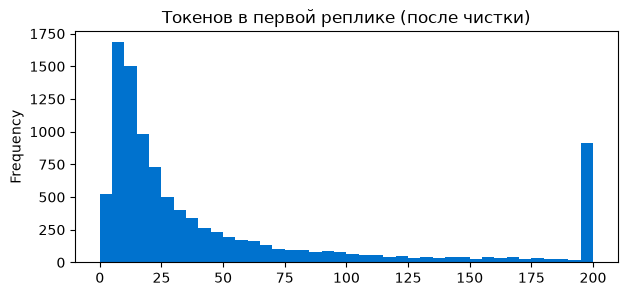

,dialog_id,raw_first,task_type
0,d094012177e,"it’s like: 1+1=2, but 1+1=2+1+1=? is undefined. <–can you tell which modulus we can possibly use in this concept and...",analysis
1,d306fbe61fe,"Can you help me train a small language model that can answer questions, i don't want to use a pretrained mode, i wan...",information_seeking
2,dd6905952c7,ask questions about a fictional voice actor i made and based on the answers describe him.,creation


In [2]:
dialogs = tu.read_dialogs(DATA)
frame = tu.to_topic_frame(dialogs)
print("диалогов:", len(frame))
print("пустая первая реплика после чистки:", (frame.first_user.str.len() == 0).sum())
print("пустое начало ответа модели:       ", (frame.first_asst.str.len() == 0).sum())
frame.first_user.str.split().str.len().clip(upper=200).plot.hist(bins=40, color="#0072CE", figsize=(7, 3),
                                                                   title="Токенов в первой реплике (после чистки)")
plt.show()
frame[["dialog_id", "raw_first", "task_type"]].head(3)

## 2. Разбиение

20% диалогов откладываем: на них проверяем, как классификатор переносит темы на новые диалоги. Темы находим только по остальным 80%. Группа — начало первой реплики: шаблонные запросы и почти-дубли не должны оказаться по обе стороны (схема `GroupKFold`, семинар 4).

In [3]:
train_idx, test_idx = next(GroupKFold(n_splits=5).split(frame, groups=frame.group))
train, test = frame.iloc[train_idx].reset_index(drop=True), frame.iloc[test_idx].reset_index(drop=True)
print("train:", len(train), " test:", len(test), " общих групп:", len(set(train.group) & set(test.group)))

train: 8000  test: 2000  общих групп: 0


## 3. Пространство для кластеризации и число тем

TF-IDF по трём источникам, затем SVD до 100 компонент (семинар 5): тексты превращаются в плотные векторы небольшой длины, где расстояния между диалогами отражают общие слова. После нормировки длины евклидово расстояние эквивалентно косинусному.

In [4]:
lsa = tu.topic_lsa(N_COMPONENTS, SEED)
Z_train = lsa.fit_transform(train)
Z_test = lsa.transform(test)
print("размер матрицы признаков:", lsa[0].transform(train.head(5)).shape[1], "-> ", Z_train.shape[1])
print("объяснённая дисперсия 100 компонент: %.2f" % lsa[1].explained_variance_ratio_.sum())

размер матрицы признаков: 63887 ->  100
объяснённая дисперсия 100 компонент: 0.13


### Сколько тем

Слишком мелкая разбивка даёт высокую однородность и низкую полноту, слишком крупная — наоборот (по условию задания). Правильное число показывают три вещи вместе:

- **силуэт** (чем выше, тем чётче границы), но на текстах он всегда невысокий, смотрим на форму кривой;
- **устойчивость**: повторяется ли разбиение при другом seed и на половине данных (ARI между запусками). Если при некотором `k` разбиение каждый раз другое, темы выдуманы алгоритмом;
- **осмысленность**: можно ли дать каждому кластеру название по карточке (раздел 4).

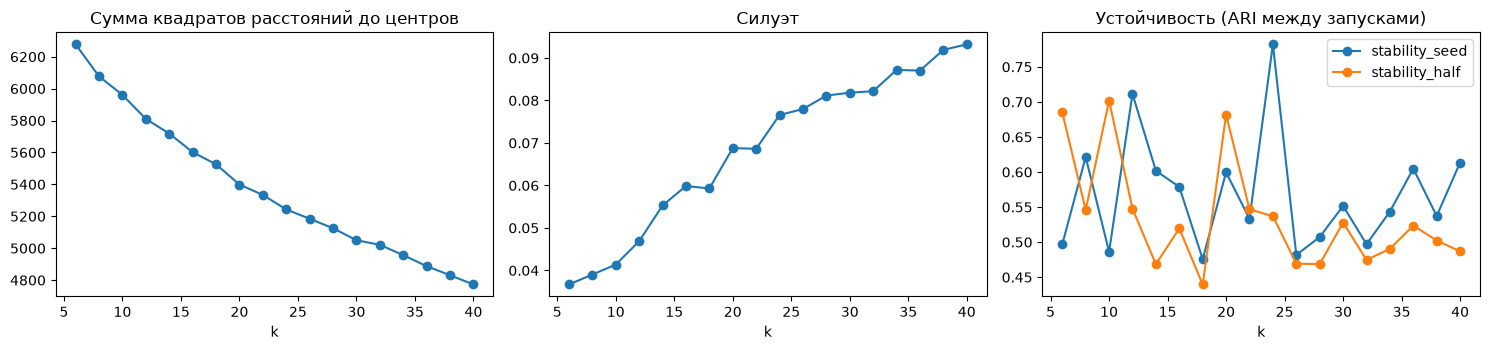

,inertia,silhouette,stability_seed,stability_half
k,,,,
6,6277.446,0.037,0.497,0.685
8,6076.857,0.039,0.621,0.546
10,5960.863,0.041,0.486,0.702
12,5810.419,0.047,0.711,0.548
14,5718.565,0.055,0.602,0.469
16,5601.878,0.060,0.579,0.519
18,5525.958,0.059,0.476,0.440
20,5399.254,0.069,0.600,0.682
22,5333.915,0.069,0.533,0.547


In [5]:
rng = np.random.default_rng(SEED)
sample = rng.choice(len(Z_train), size=min(3000, len(Z_train)), replace=False)
half = rng.permutation(len(Z_train))[: len(Z_train) // 2]
rows = []
for k in range(6, 41, 2):
    a = KMeans(k, n_init=3, random_state=SEED).fit(Z_train)
    b = KMeans(k, n_init=3, random_state=SEED + 1).fit(Z_train)
    h = KMeans(k, n_init=3, random_state=SEED + 2).fit(Z_train[half])
    rows.append({"k": k, "inertia": a.inertia_,
                 "silhouette": silhouette_score(Z_train[sample], a.labels_[sample]),
                 "stability_seed": adjusted_rand_score(a.labels_, b.labels_),
                 "stability_half": adjusted_rand_score(a.labels_, h.predict(Z_train))})
sweep = pd.DataFrame(rows).set_index("k")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
sweep.inertia.plot(ax=axes[0], marker="o", title="Сумма квадратов расстояний до центров")
sweep.silhouette.plot(ax=axes[1], marker="o", title="Силуэт")
sweep[["stability_seed", "stability_half"]].plot(ax=axes[2], marker="o", title="Устойчивость (ARI между запусками)")
plt.tight_layout(); plt.show()
display(sweep.round(3))

### Сравнение алгоритмов

Те же признаки, подвыборка 3 000 диалогов (агломеративная кластеризация и GMM на всех данных долгие). Чтобы сравнивать без эталона, смотрим силуэт, индекс Калински — Харабаша (больше лучше) и Дэвиса — Болдина (меньше лучше), и согласие с k-means (ARI).

In [6]:
Zs = Z_train[sample]
def scores(labels, ref=None):
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    ok = 1 < n_clusters < mask.sum()
    return {"тем": n_clusters, "шум": 1 - mask.mean(),
            "силуэт": silhouette_score(Zs[mask], labels[mask]) if ok else np.nan,
            "Калински — Харабаш": calinski_harabasz_score(Zs[mask], labels[mask]) if ok else np.nan,
            "Дэвис — Болдин": davies_bouldin_score(Zs[mask], labels[mask]) if ok else np.nan,
            "ARI с k-means": adjusted_rand_score(ref, labels) if ref is not None else np.nan}

km_s = KMeans(K, n_init=5, random_state=SEED).fit_predict(Zs)
kdist = NearestNeighbors(n_neighbors=10).fit(Zs).kneighbors(Zs)[0][:, -1]
methods = {
    "k-means": km_s,
    "агломеративная (Уорд)": AgglomerativeClustering(K, linkage="ward").fit_predict(Zs),
    "GMM (диагональные ковариации)": GaussianMixture(K, covariance_type="diag", random_state=SEED).fit_predict(Zs),
    "DBSCAN": DBSCAN(eps=np.median(kdist), min_samples=10).fit_predict(Zs),
}
display(pd.DataFrame({name: scores(lab, km_s) for name, lab in methods.items()}).T.round(3))

,тем,шум,силуэт,Калински — Харабаш,Дэвис — Болдин,ARI с k-means
k-means,16.0,0.000,0.065,48.543,3.342,1.000
агломеративная (Уорд),16.0,0.000,0.037,39.505,3.493,0.246
GMM (диагональные ковариации),16.0,0.000,0.027,37.790,3.905,0.241
DBSCAN,6.0,0.171,-0.054,4.035,2.288,-0.007


DBSCAN на текстах обычно даёт одну огромную группу и много шума: плотность в таком пространстве почти однородна, поэтому выбираем **k-means**. У него есть и практическое преимущество: новый диалог относится к ближайшему центру. Агломеративная кластеризация и GMM нужны как проверка: если разбиения похожи на k-means (высокий ARI), темы не артефакт алгоритма.

**Выберите число тем по графикам и таблице выше и впишите в `K` в разделе 0.** Хорошая точка: силуэт не падает, а устойчивость ещё высокая. Если хочется мельче, можно взять большее `K` и объединить похожие кластеры вручную в разделе 4.

## 4. Темы: карточки, названия, описания

In [7]:
km = KMeans(K, n_init=10, random_state=SEED).fit(Z_train)
train_cluster, test_cluster = km.labels_, km.predict(Z_test)

X_train = lsa[0].transform(train)                     # TF-IDF до SVD: из него берём слова
terms = np.array([n.split("__", 1)[1] for n in lsa[0].get_feature_names_out()])

def show_cards(n_terms=10, n_examples=3):
    for c in np.argsort(-np.bincount(train_cluster, minlength=K)):
        idx = np.where(train_cluster == c)[0]
        mean_vec = np.asarray(X_train[idx].mean(axis=0)).ravel()
        top = list(dict.fromkeys(terms[mean_vec.argsort()[::-1][: n_terms * 3]]))[:n_terms]
        closest = idx[np.argsort(((Z_train[idx] - km.cluster_centers_[c]) ** 2).sum(axis=1))[:n_examples]]
        print(f"=== кластер {c}: {len(idx) / len(train):.1%} диалогов ===")
        print("слова:", ", ".join(top))
        for i in closest:
            print("   •", train.raw_first.iloc[i][:150].replace("\n", " "))
show_cards()

=== кластер 2: 15.4% диалогов ===
слова: for, i, list, is, pleas, about, translat, with, explain, name
   • accents simlar to estonian
   • maerhana
   • Premium The Royal Stainless Steel Spoon Necklace Vintage Crown Mini Tea Stainless Steel Spoon Pendant Royal Alice Snuff Necklace， Sliver
=== кластер 15: 10.5% диалогов ===
слова: for, that, on, is, this, with, be, it, as, or
   • The introduction paragraph of the Guide buddy proposal (including 5 parts: Problem, Evidence/Prevalence of the problem, Target Group Affected, Why the
   • Using this article is deregulation good in the air travel industry? In 2009, despite almost three decades of falling airfares and rising passenger num
   • Please modify this paragraph: The Master’s degree program in Biochemistry was initiated in 1973 and was one of the first postgraduate programmes to be
=== кластер 7: 10.2% диалогов ===
слова: zzcode, code, this, if, zzmath, file, zzcode zzmath, for, i, from
   • how can I call this audio <audio> from my

Прочитайте карточки и заполните словарь ниже. Несколько кластеров можно отдать одной теме (так объединяются мелкие соседи). Кластеры без названия получают временное имя `topic_NN`. Описание — одна-две строки: что входит в тему. Дальше всё считается по названным темам.

In [8]:
CLUSTER_TO_TOPIC = {
    # 0: "программирование",
    # 1: "творческое письмо",
}
TOPIC_DESCRIPTIONS = {
    # "программирование": "написание и отладка кода, вопросы по языкам и библиотекам",
}
topic_of_cluster = {c: CLUSTER_TO_TOPIC.get(c, f"topic_{c:02d}") for c in range(K)}
y_train = pd.Series(train_cluster).map(topic_of_cluster).to_numpy()
y_test = pd.Series(test_cluster).map(topic_of_cluster).to_numpy()
print("тем после объединения:", len(set(y_train)))

тем после объединения: 16


In [9]:
# таблица тем для отчёта: название, описание, доля, характерные диалоги
rows = []
for name in pd.Series(y_train).value_counts().index:
    idx = np.where(y_train == name)[0]
    nearest = idx[np.argsort(((Z_train[idx] - Z_train[idx].mean(axis=0)) ** 2).sum(axis=1))[:3]]
    rows.append({"тема": name, "описание": TOPIC_DESCRIPTIONS.get(name, ""), "доля": len(idx) / len(train),
                 "диалоги": "; ".join(train.dialog_id.iloc[nearest]),
                 "примеры": " | ".join(train.raw_first.iloc[i][:80].replace("\n", " ") for i in nearest)})
topics_table = pd.DataFrame(rows)
topics_table.to_csv(os.path.join(tu.ARTIFACTS, "topics_table.csv"), index=False)
display(topics_table.round(3))

,тема,описание,доля,диалоги,примеры
0,topic_02,,0.154,d1d035c710c; de22a37eca2; d751fc98b2d,accents simlar to estonian | maerhana | Premium The Royal Stainless Steel Spoon Necklace Vintage Crown Mini Tea Stai...
1,topic_15,,0.105,d0865469d3b; d73d5ce7de4; df1aed20e14,The introduction paragraph of the Guide buddy proposal (including 5 parts: Probl | Using this article is deregulatio...
2,topic_07,,0.102,d3d2a1dc4a1; dd00cc5be51; d35249332b8,"how can I call this audio <audio> from my python code? @app.get(""/audio"") async | the result of the below code give..."
3,topic_09,,0.093,d3b6f69e071; da0f088d9bc; d3473df131f,"whats the most common hashing alogrithm nowadays? | What spices are toxic for cat and dogs: garlic, onion, parsley, ..."
4,topic_06,,0.088,d138c7ad113; dfd8cd21c56; d835ecefb7b,"What is my problem? Today is June 20, 2023; and, I will try my best to explain m | Hi there. I hope you can help me ..."
5,topic_05,,0.076,d4ca91716b3; d66f9f59ce4; dd0d27c483c,"Willa Cather's 1913 novel, O Pioneers!, tells the story of the Bergson family, S | Act as n editor at a publishers: ..."
6,topic_01,,0.064,d8bd761f551; dec65362fc6; dd8c2e8bbc1,Can you run a design sprint? | Can you do emojis? 🤔 | can you parse a web page ?
7,topic_03,,0.063,d25d47e18d7; da25342331d; de0a5cc84ca,"BACKWARD PHASE In this phase, the initial job sequence is developed. The sequent | In this question we will think ab..."
8,topic_04,,0.057,d13c322c8ee; d082565f361; da761375ab4,Write a complete Porchlight Entertainment catalog | Write a CBBC schedule | write a commercial for spicy hotdogs wit...
9,topic_00,,0.040,dd9d9ddbbba; d182eccb230; dbc002afc25,Give me a wise advice | give me a full body bullworker workout | Give me a poem


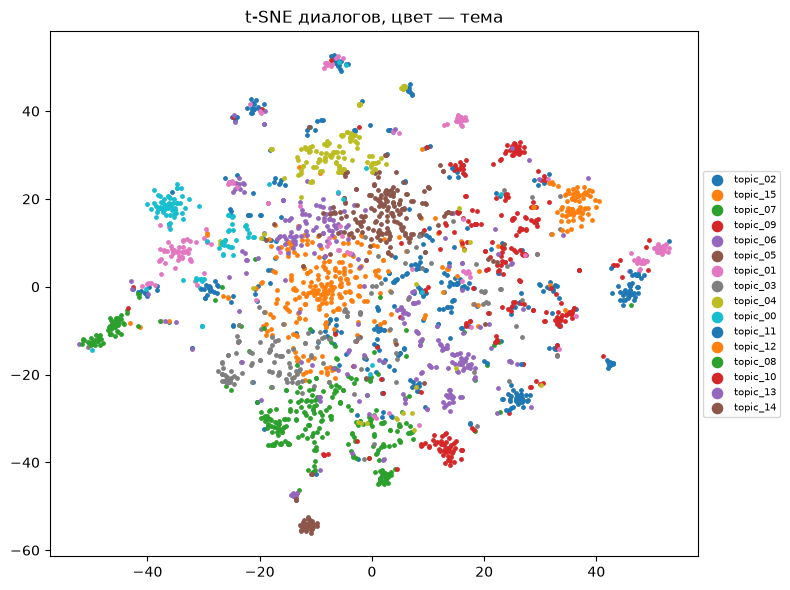

In [10]:
# карта: t-SNE по подвыборке, цвет — тема (семинар 5)
sub = rng.choice(len(Z_train), size=min(2500, len(Z_train)), replace=False)
emb = TSNE(2, init="pca", metric="cosine", perplexity=30, random_state=SEED).fit_transform(Z_train[sub])
plt.figure(figsize=(8, 6))
for name in pd.Series(y_train[sub]).value_counts().index:
    m = y_train[sub] == name
    plt.scatter(emb[m, 0], emb[m, 1], s=6, label=name)
plt.legend(markerscale=3, fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5)); plt.title("t-SNE диалогов, цвет — тема")
plt.tight_layout(); plt.show()

## 5. Сверка с `task_type`

У 3 000 диалогов есть разметка `task_type` (информационный запрос, создание текста и т. д.). Это другая ось: тип задачи, а не тема. Если бы наши темы совпадали с ней, мы бы просто пересказали `task_type`. Ожидаем умеренную связь.

In [11]:
lab = train.task_type.notna().to_numpy()
print("размечено по task_type в train:", lab.sum())
print("NMI тем и task_type: %.3f   V-мера: %.3f" % (
    normalized_mutual_info_score(train.task_type[lab], y_train[lab]), v_measure_score(train.task_type[lab], y_train[lab])))
display(pd.crosstab(pd.Series(y_train[lab], name="тема"), train.task_type[lab].rename("task_type"), normalize="index").round(2))

размечено по task_type в train: 2405
NMI тем и task_type: 0.068   V-мера: 0.068


task_type,analysis,creation,information_seeking,open-ended_discovery
тема,,,,
topic_00,0.02,0.30,0.67,0.01
topic_01,0.03,0.20,0.70,0.07
topic_02,0.04,0.31,0.60,0.05
topic_03,0.08,0.15,0.76,0.01
topic_04,0.00,0.76,0.24,0.01
topic_05,0.06,0.64,0.26,0.04
topic_06,0.04,0.31,0.61,0.04
topic_07,0.03,0.24,0.72,0.00
topic_08,0.03,0.40,0.56,0.01


## 6. Классификатор

Цель: чтобы новый диалог получал одну из наших тем. Все модели учатся на тех же `train` с метками-темами и оцениваются на тех же `test` (метка теста — ближайший центр k-means, то есть то, что получил бы диалог, если бы участвовал в кластеризации). Метрики — те, которыми задание сравнивает разбиения: ARI, NMI, однородность, полнота, V-мера, чистота; рядом accuracy и macro-F1. Это одна таблица для всех моделей.

Три базовые: Naive Bayes, логистическая регрессия, линейный SVM на TF-IDF. Две свои: SVD + ближайшие соседы и SVD + SVM с RBF-ядром. Гиперпараметры выбирает `GridSearchCV` на train по macro-F1 (группы не разрываются); тест используется один раз. У двух dummy-моделей ARI около нуля, это нижняя граница.

In [12]:
MODELS = tu.topic_models(SEED)
inner_cv = GroupKFold(n_splits=3)
fitted, preds, rows = {}, {}, []
for name, (pipe, grid) in MODELS.items():
    if grid:
        search = GridSearchCV(pipe, grid, cv=inner_cv, scoring="f1_macro", n_jobs=-1)
        search.fit(train, y_train, groups=train.group)
        model, cv_f1, params = search.best_estimator_, search.best_score_, search.best_params_
    else:
        model, cv_f1, params = clone(pipe).fit(train, y_train), np.nan, {}
    fitted[name], preds[name] = model, model.predict(test)
    rows.append({"model": name, "cv_macro_f1": cv_f1, **tu.topic_metrics(y_test, preds[name]), "params": params})
topic_table = pd.DataFrame(rows)
COLS = ["model", "cv_macro_f1", "accuracy", "macro_f1", "ARI", "NMI", "однородность", "полнота", "V-мера", "чистота"]
display(topic_table[COLS].round(3))

,model,cv_macro_f1,accuracy,macro_f1,ARI,NMI,однородность,полнота,V-мера,чистота
0,dummy_one_topic,NaN,0.132,0.015,0.000,0.000,0.000,1.000,0.000,0.132
1,dummy_random_topics,NaN,0.062,0.058,0.001,0.025,0.026,0.024,0.025,0.158
2,nb,0.620,0.663,0.632,0.425,0.499,0.486,0.513,0.499,0.663
3,logreg,0.930,0.907,0.924,0.785,0.830,0.827,0.833,0.830,0.907
4,linear_svm,0.910,0.899,0.911,0.778,0.812,0.814,0.810,0.812,0.899
5,own_lsa_knn,0.862,0.842,0.870,0.660,0.732,0.728,0.736,0.732,0.842
6,own_lsa_rbf_svm,0.932,0.932,0.940,0.851,0.861,0.861,0.861,0.861,0.932


лучшая по ARI на тесте: own_lsa_rbf_svm {'m__C': 10}


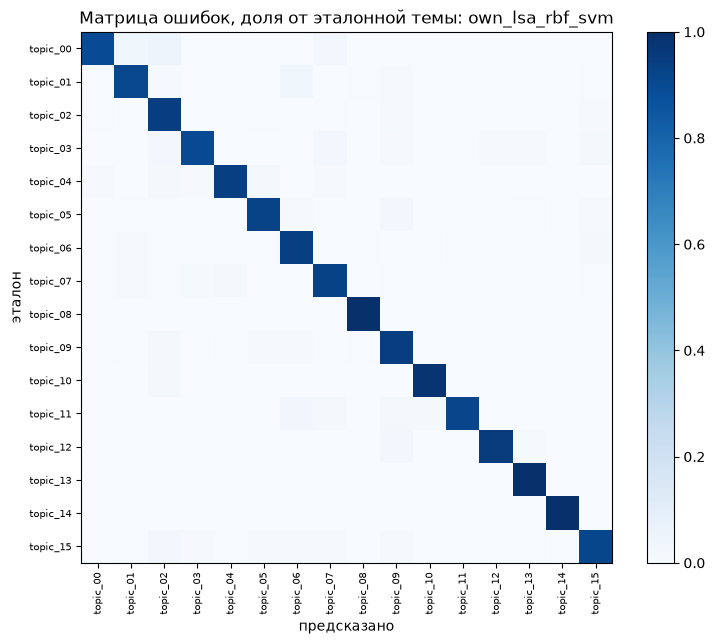

In [13]:
best = topic_table.loc[~topic_table.model.str.startswith("dummy")].sort_values("ARI").iloc[-1].model
print("лучшая по ARI на тесте:", best, topic_table.set_index("model").loc[best, "params"])
names = sorted(set(y_train))
cm = pd.crosstab(pd.Series(y_test, name="эталон"), pd.Series(preds[best], name="предсказано")).reindex(index=names, columns=names, fill_value=0)
share = cm.div(cm.sum(axis=1).clip(lower=1), axis=0)
plt.figure(figsize=(8, 6.5)); plt.imshow(share, cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(len(names)), names, rotation=90, fontsize=7); plt.yticks(range(len(names)), names, fontsize=7)
plt.xlabel("предсказано"); plt.ylabel("эталон"); plt.title(f"Матрица ошибок, доля от эталонной темы: {best}"); plt.grid(False); plt.colorbar(); plt.tight_layout(); plt.show()

## 7. Проверка устойчивости тем

Идея: если тема настоящая, её можно узнать по *другим* признакам. Строим темы только по первой реплике пользователя, а классификатор учим по другому источнику: только по началу ответа модели. Если ARI между такими темами и предсказаниями высокий, темы отражают смысл диалога, а не особенности одного признака. Заодно сравним разбиение только по первой реплике с основным.

In [14]:
lsa_a = make_pipeline(ColumnTransformer([("first", tu.topic_tfidf(), "first_user")]),
                      TruncatedSVD(N_COMPONENTS, random_state=SEED), Normalizer())
Za_train = lsa_a.fit_transform(train)
km_a = KMeans(K, n_init=10, random_state=SEED).fit(Za_train)
ya_test = km_a.predict(lsa_a.transform(test))

view_b = Pipeline([("f", ColumnTransformer([("asst", tu.topic_tfidf(), "first_asst")])),
                   ("m", LogisticRegression(C=10, class_weight="balanced", max_iter=2000))])
view_b.fit(train, km_a.labels_)
print("темы по первой реплике vs предсказание только по ответу модели:")
print({k: round(v, 3) for k, v in tu.partition_scores(ya_test, view_b.predict(test)).items()})
print("темы по первой реплике vs основные темы (разные признаки, тот же алгоритм):")
print({k: round(v, 3) for k, v in tu.partition_scores(y_test, ya_test).items()})

темы по первой реплике vs предсказание только по ответу модели:
{'ARI': 0.105, 'NMI': 0.159, 'однородность': 0.159, 'полнота': 0.159, 'V-мера': 0.159, 'чистота': np.float64(0.338)}
темы по первой реплике vs основные темы (разные признаки, тот же алгоритм):
{'ARI': 0.531, 'NMI': 0.62, 'однородность': 0.623, 'полнота': 0.618, 'V-мера': 0.62, 'чистота': np.float64(0.742)}


## 8. Разбор ошибок

In [15]:
conf = cm.stack().rename("n").reset_index()
conf = conf[conf["эталон"] != conf["предсказано"]].sort_values("n", ascending=False).head(6)
display(conf)
for _, r in conf.head(3).iterrows():
    mask = (y_test == r["эталон"]) & (preds[best] == r["предсказано"])
    print(f"\n=== эталон «{r['эталон']}», предсказано «{r['предсказано']}»: {mask.sum()} диалогов ===")
    for text in test.raw_first[mask].head(4):
        print("   •", text[:160].replace("\n", " "))

,эталон,предсказано,n
242,topic_15,topic_02,7
22,topic_01,topic_06,5
89,topic_05,topic_09,5
41,topic_02,topic_09,4
116,topic_07,topic_04,4
2,topic_00,topic_02,4



=== эталон «topic_15», предсказано «topic_02»: 7 диалогов ===
   • Whats the jailtime for this case: evidence of emails spam phishing, stolen and sold over 50k ccs, used himself some stolen cards and also generated ones probabl
   • introduce AI industry in UAE in full details
   • lyrics of a sound bath meditation for police officers
   • In the vien of ISO7010 and related signs, design a hypothetical series of signs describing the boarding process for an "arieal tramway" including any saftey war

=== эталон «topic_01», предсказано «topic_06»: 5 диалогов ===
   • Can you make a workout routine with one break day a week for getting an aesthetic body I only have a single 15 lb dumbbell
   • Let’s play a game where you must logically contradict everything I say. You must always respond with “no” and provide a logical counterargument
   • Hi, i am accessibility consultant, can you please provide short description of 1. Perceivable , 2. Operable , 3. Understandable , 4. Robust
   • I want

Типичные причины: короткие реплики без темы («continue», «hi»); диалоги, где тема сменилась по ходу; пограничные кластеры, которые можно было бы объединить. Что из этого видно по примерам, записать в отчёт.

## 9. Метрики реакции по темам

По заданию нужна таблица метрик **лучшей модели реакции** по нашим темам. Тема каждого диалога берётся из лучшего классификатора тем, а предсказания реакции — из ноутбука задачи 1. В нём в конце раздела 8 (после таблиц теста) нужна одна строка:

```python
test.assign(pred=test_pred[best])[["dialog_id", "reaction", "pred"]].to_csv(os.path.join(tu.ARTIFACTS, "reaction_test_predictions.csv"), index=False)
```

In [16]:
topic_all = pd.DataFrame({"dialog_id": frame.dialog_id, "topic": fitted[best].predict(frame)})
topic_all.to_csv(os.path.join(tu.ARTIFACTS, "topic_assignments.csv"), index=False)
path = os.path.join(tu.ARTIFACTS, "reaction_test_predictions.csv")
if os.path.exists(path):
    merged = pd.read_csv(path).merge(topic_all, on="dialog_id")
    display(tu.metrics_by_group(merged, "topic", "reaction", "pred").round(3))
else:
    print("нет", path, "- сначала сохраните предсказания реакции в ноутбуке задачи 1")

нет /home/salexq/ml_dafe_mipt/homeworks/hw1/solution/artifacts/reaction_test_predictions.csv - сначала сохраните предсказания реакции в ноутбуке задачи 1


## 10. Сохранение

Финальные модели переобучаем на всех 10 000 диалогах (меткам темы — кластеры) с выбранными параметрами, кладём в `artifacts/` вместе с версиями библиотек. Оценки в отчёте остаются теми, что получены на отложенных 20%.

In [17]:
# full = pd.concat([train, test], ignore_index=True)
# y_full = np.concatenate([y_train, y_test])
# meta = {"sklearn": sklearn.__version__, "python": platform.python_version(), "K": K, "n_components": N_COMPONENTS,
#         "topics": sorted(set(y_full)), "models": {}}
# for name in MODELS:
#     model = clone(fitted[name]).fit(full, y_full)
#     joblib.dump(model, os.path.join(tu.ARTIFACTS, f"topic_{name}.joblib"))
#     row = topic_table[topic_table.model == name].iloc[0]
#     meta["models"][name] = {"ARI_test": round(float(row.ARI), 4), "macro_f1_test": round(float(row.macro_f1), 4),
#                             "params": {k: str(v) for k, v in row.params.items()}}
# with open(os.path.join(tu.ARTIFACTS, "topic_meta.json"), "w", encoding="utf-8") as f:
#     json.dump(meta, f, ensure_ascii=False, indent=1)
# loaded = tu.init_topic_models()
# print(sorted(loaded), "| темы в модели:", len(loaded["logreg"].classes_))